In [1]:
import h5py 

with h5py.File("../data/raw/test.h5", "r") as f:
    
    def mostrar(nombre, objeto):
        if isinstance(objeto, h5py.Dataset):
            print(f"{nombre:40s} forma {objeto.shape}  tipo {objeto.dtype}")
    f.visititems(mostrar)


table/_i_table/index/abounds             forma (384,)  tipo int64
table/_i_table/index/bounds              forma (3, 127)  tipo int64
table/_i_table/index/indices             forma (3, 131072)  tipo uint32
table/_i_table/index/indicesLR           forma (131072,)  tipo uint32
table/_i_table/index/mbounds             forma (384,)  tipo int64
table/_i_table/index/mranges             forma (3,)  tipo int64
table/_i_table/index/ranges              forma (3, 2)  tipo int64
table/_i_table/index/sorted              forma (3, 131072)  tipo int64
table/_i_table/index/sortedLR            forma (131201,)  tipo int64
table/_i_table/index/zbounds             forma (384,)  tipo int64
table/table                              forma (404000,)  tipo [('index', '<i8'), ('values_block_0', '<f4', (804,)), ('values_block_1', '<i8', (2,))]


In [2]:
pip install hdf5plugin


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 MB 41.5 MB/s  0:00:01 eta 0:00:010:00:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import h5py
import hdf5plugin        # <-- nueva: registra Blosc y otros descompresores
import numpy as np

with h5py.File("../data/raw/test.h5", "r") as f:
    filas = f["table/table"][0:100_000]

numeros = filas["values_block_0"]
etiquetas = filas["values_block_1"]

print(numeros.shape, numeros.dtype)
print(etiquetas.shape)
print(f"Memoria: {numeros.nbytes / 1e6:.0f} MB")
print("Valores de las etiquetas:", np.unique(etiquetas[:, 0]), np.unique(etiquetas[:, 1]))

(100000, 804) float32
(100000, 2)
Memoria: 322 MB
Valores de las etiquetas: [1] [0 1]


In [4]:
y = etiquetas[:, 1]
print("Jets top:", (y == 1).sum(), "   Jets QCD:", (y == 0).sum())

Jets top: 49430    Jets QCD: 50570


In [5]:
p = numeros[:, :800].reshape(-1, 200, 4)
E, px, py, pz = p[..., 0], p[..., 1], p[..., 2], p[..., 3]

hay = E > 0
masa2 = E[hay]**2 - (px[hay]**2 + py[hay]**2 + pz[hay]**2)
print("Partículas reales:", hay.sum())
print("Fracción con E² ≥ p²:", np.mean(masa2 > -1e-3 * E[hay]**2))

Partículas reales: 4897415
Fracción con E² ≥ p²: 1.0


pT del jet: de 550 a 650 GeV


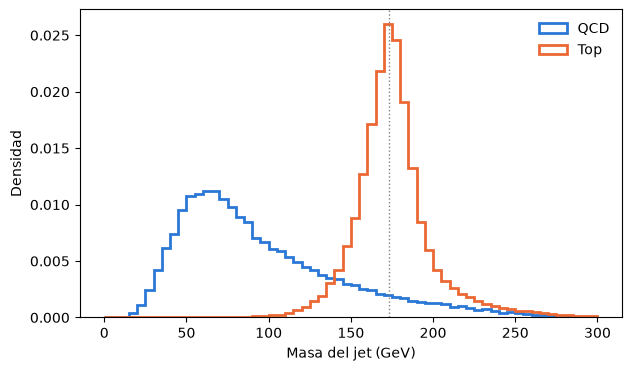

In [8]:
import matplotlib.pyplot as plt

# guardar en float32, calcular en float64 
E64, px64, py64, pz64 = (c.astype(np.float64) for c in (E, px, py, pz))

jet_E  = E64.sum(axis=1)
jet_px = px64.sum(axis=1)
jet_py = py64.sum(axis=1)
jet_pz = pz64.sum(axis=1)

jet_pt   = np.sqrt(jet_px**2 + jet_py**2)
jet_masa = np.sqrt(np.clip(jet_E**2 - (jet_px**2 + jet_py**2 + jet_pz**2), 0, None))
n_part   = hay.sum(axis=1)

print(f"pT del jet: de {jet_pt.min():.0f} a {jet_pt.max():.0f} GeV")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 300, 61)
ax.hist(jet_masa[y == 0], bins, histtype="step", lw=2, color="#2a78d6", label="QCD", density=True)
ax.hist(jet_masa[y == 1], bins, histtype="step", lw=2, color="#eb6834", label="Top", density=True)
ax.axvline(173, color="gray", ls=":", lw=1)
ax.set_xlabel("Masa del jet (GeV)")
ax.set_ylabel("Densidad")
ax.legend(frameon=False)
plt.show()

AUC usando solo la masa: 0.927


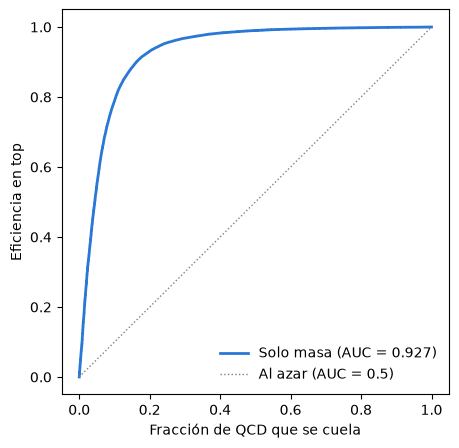

In [9]:
from sklearn.metrics import roc_auc_score, roc_curve

# más próximo a 173 GeV
puntaje_masa = -np.abs(jet_masa - 173)

auc = roc_auc_score(y, puntaje_masa)
print(f"AUC usando solo la masa: {auc:.3f}")

fpr, tpr, _ = roc_curve(y, puntaje_masa)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color="#2a78d6", lw=2, label=f"Solo masa (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1, label="Al azar (AUC = 0.5)")
ax.set_xlabel("Fracción de QCD que se cuela")
ax.set_ylabel("Eficiencia en top")
ax.legend(frameon=False)
plt.show()

In [10]:
for ancho in [5, 10, 20, 40, 80, 150]:
    dentro = np.abs(jet_masa - 173) < ancho
    efic_top = dentro[y == 1].mean()
    cuela_qcd = dentro[y == 0].mean()
    print(f"ventana ±{ancho:3d} GeV:   top dentro = {efic_top:.2f}   QCD dentro = {cuela_qcd:.2f}")

ventana ±  5 GeV:   top dentro = 0.25   QCD dentro = 0.02
ventana ± 10 GeV:   top dentro = 0.46   QCD dentro = 0.04
ventana ± 20 GeV:   top dentro = 0.72   QCD dentro = 0.08
ventana ± 40 GeV:   top dentro = 0.91   QCD dentro = 0.17
ventana ± 80 GeV:   top dentro = 0.98   QCD dentro = 0.41
ventana ±150 GeV:   top dentro = 1.00   QCD dentro = 0.99


In [11]:
# 1. Coordenadas de cada partícula
pt_i = np.sqrt(px64**2 + py64**2)
with np.errstate(divide="ignore", invalid="ignore"):
    eta_i = np.where(hay, np.arcsinh(pz64 / pt_i), 0.0)
phi_i = np.arctan2(py64, px64)

# 2. Coordenadas del eje del jet
jet_eta = np.arcsinh(jet_pz / jet_pt)
jet_phi = np.arctan2(jet_py, jet_px)

# 3. Distancia de cada partícula al eje
deta = eta_i - jet_eta[:, None]
dphi = (phi_i - jet_phi[:, None] + np.pi) % (2 * np.pi) - np.pi
dR = np.where(hay, np.hypot(deta, dphi), 0.0)

# 4. Las tres variables de subestructura
pt_total   = pt_i.sum(axis=1)
anchura    = (pt_i * dR).sum(axis=1) / pt_total
frac_lider = pt_i.max(axis=1) / pt_total

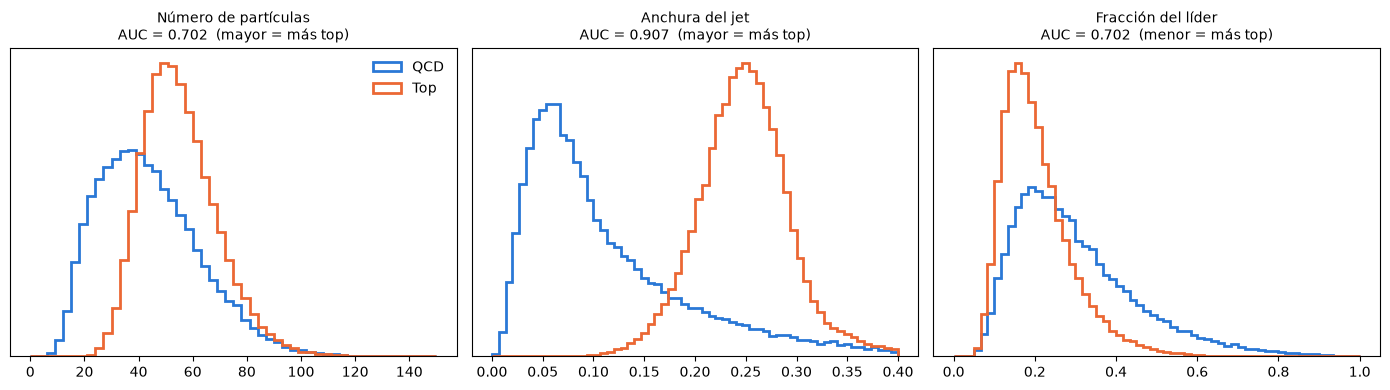

In [12]:
variables = {
    "Número de partículas": (n_part,     np.arange(0, 151, 3)),
    "Anchura del jet":      (anchura,    np.linspace(0, 0.4, 61)),
    "Fracción del líder":   (frac_lider, np.linspace(0, 1, 61)),
}

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (nombre, (valores, bins)) in zip(ejes, variables.items()):
    ax.hist(valores[y == 0], bins, histtype="step", lw=2, color="#2a78d6", label="QCD", density=True)
    ax.hist(valores[y == 1], bins, histtype="step", lw=2, color="#eb6834", label="Top", density=True)

    auc = roc_auc_score(y, valores)
    sentido = "mayor = más top"
    if auc < 0.5:
        auc, sentido = 1 - auc, "menor = más top"

    ax.set_title(f"{nombre}\nAUC = {auc:.3f}  ({sentido})", fontsize=10)
    ax.set_yticks([])

ejes[0].legend(frameon=False)
plt.tight_layout()
plt.show()